# **1. Bussines Understanding**


## **1.1 Latar Belakang**

Sebuah perusahaan atau platform jual beli kendaraan ingin membangun sistem
kecerdasan buatan untuk memperkirakan harga jual mobil
bekas secara otomatis berdasarkan karakteristik kendaraan dan kondisi
penggunaannya. Sistem ini bertujuan membantu penjual maupun pembeli dalam
memperoleh estimasi harga kendaraan tanpa harus melakukan penilaian secara
manual.

## **1.2 Tujuan**

Membangun kecedasan buatan untuk memprediksi harga jual mobil bekas berdasarkan karakteristik kendaraan dan kondisi penggunaannya tanpa harus melakukan penilaian atau peninjauan secara manual.

## **1.3 Masalah**

Dalam proses penilaian atau peninjauan mobil bekas, penjual atau pembeli masih memperkirakan harga secara manual sehingga itu memhabiskan waktu yang lama dan tidak efisien.

## **1.4 Solusi**

Membangun kecedasan buatan atau machine learning untuk memprediksi harga jual mobil bekas secara otomatis dengan menggunakan machine learning menggunakan algoritma Decision Tree.

## **1.5 Deskripsi Tabel**

`Fitur Input (8 kolom atribut kendaraan yang digunakan untuk memperkirakan hargajual, ya) meliputi:`
- Car_Name: Nama atau model kendaraan yang dijual.
- Year: Tahun produksi kendaraan.
- Present_Price: Harga kendaraan saat ini berdasarkan data yang tersedia.
- Kms_Driven: Jarak tempuh kendaraan.
- Fuel_Type: Jenis bahan bakar yang digunakan kendaraan (Petrol, Diesel,
CNG).
- Seller_Type: Jenis penjual kendaraan (Dealer atau Individual).
- Transmission: Jenis transmisi kendaraan (Manual atau Automatic).
- Owner: Informasi jumlah atau kategori kepemilikan sebelumnya berdasarkan
nilai yang tercatat dalam dataset.

`Target (Y): `
- Kolom Selling_Price yang berisi nilai harga jual kendaraan dan menjadi
variabel yang akan diprediksi oleh model Machine Learning.`


# **2. Data Preprocessing**

In [452]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tkinter as tk
from tkinter import ttk
from tkinter import filedialog
from tkinter import messagebox


In [453]:
df = pd.read_csv('../dataset/automobile_dataset.csv')

In [454]:
df.head()

,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


In [455]:
print("Jumlah Baris:", df.shape[0])
print('=======================================')
print("Jumlah Kolom Column:", df.shape[1])
print('=======================================')
print('Frame Data:', df.size)


Jumlah Baris: 5500
Jumlah Kolom Column: 18
Frame Data: 99000


In [456]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Make              5500 non-null   str    
 1   Model             5500 non-null   str    
 2   Year              5500 non-null   int64  
 3   Fuel_Type         5500 non-null   str    
 4   Transmission      4673 non-null   str    
 5   Engine_Size       4656 non-null   float64
 6   Mileage           5500 non-null   int64  
 7   Horsepower        4700 non-null   float64
 8   Torque            4701 non-null   float64
 9   Owners            5500 non-null   int64  
 10  Accident_History  4688 non-null   float64
 11  Service_History   4645 non-null   str    
 12  Color             4697 non-null   str    
 13  Body_Type         5500 non-null   str    
 14  Drivetrain        5500 non-null   str    
 15  Fuel_Efficiency   4706 non-null   float64
 16  Location          4718 non-null   str    
 17  Sellin

,Year,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Fuel_Efficiency,Selling_Price
count,5500.000000,4656.000000,5500.000000,4700.000000,4701.000000,5500.000000,4688.000000,4706.000000,5500.000000
mean,2014.494000,2.450623,114529.481636,198.236596,189.014678,2.464000,0.408063,34.179771,12319.873636
std,5.789745,0.843913,91858.943421,55.678165,56.631309,1.280022,0.491527,15.085473,12658.478862
min,2005.000000,0.000000,100.000000,97.000000,77.000000,1.000000,0.000000,10.000000,500.000000
25%,2009.000000,2.000000,39112.000000,160.000000,151.000000,1.000000,0.000000,27.000000,1304.750000
50%,2014.000000,2.400000,96926.500000,187.000000,178.000000,2.000000,0.000000,32.000000,8586.000000
75%,2020.000000,3.000000,172757.500000,231.000000,219.000000,3.000000,1.000000,37.000000,19097.500000
max,2024.000000,5.700000,536731.000000,434.000000,443.000000,5.000000,1.000000,141.000000,86692.000000


In [457]:
hasil_na = pd.DataFrame({'Mising Value': df.isnull().sum(), 'Persentase Missing Value': df.isnull().sum() / len(df) * 100})
hasil_na.sort_values(by='Persentase Missing Value', ascending=False)

,Mising Value,Persentase Missing Value
Service_History,855,15.545455
Engine_Size,844,15.345455
Transmission,827,15.036364
Accident_History,812,14.763636
Color,803,14.600000
Horsepower,800,14.545455
Torque,799,14.527273
Fuel_Efficiency,794,14.436364
Location,782,14.218182
Make,0,0.000000


In [458]:
print('Jumlah Duplicate :', df.duplicated().sum())

Jumlah Duplicate : 0


# **3. Exploratory Data Analysis**

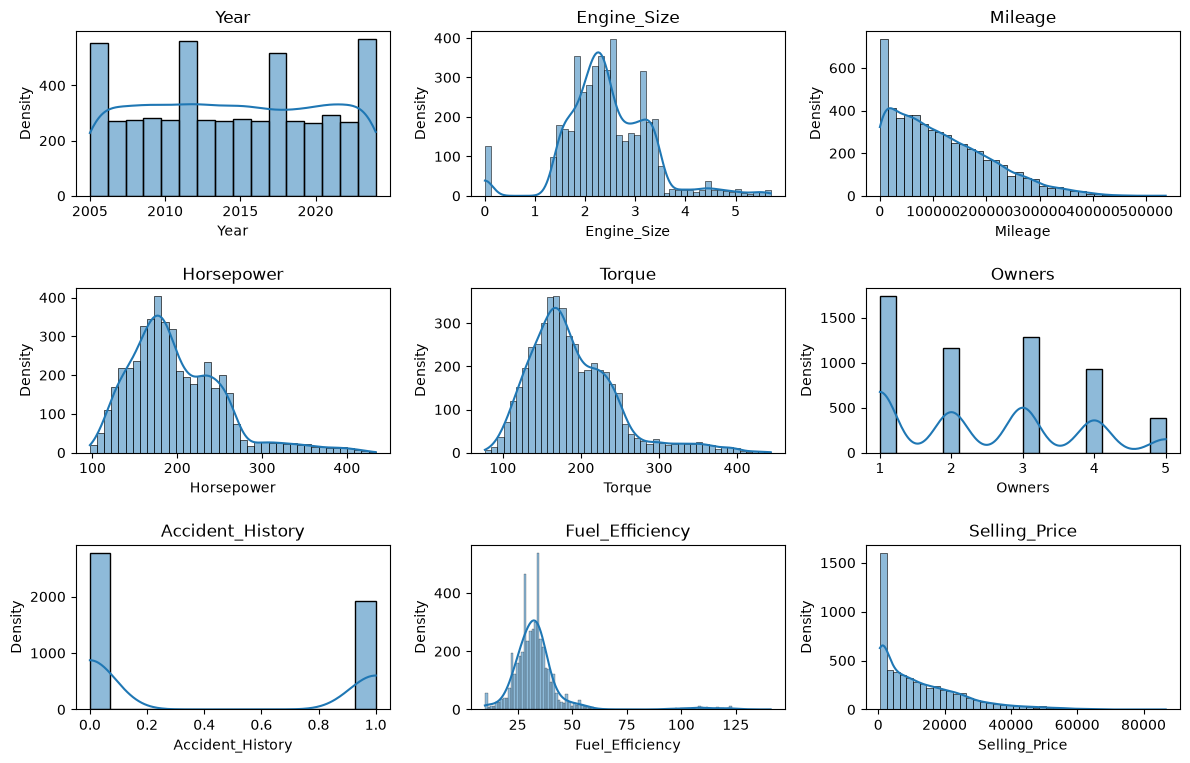

In [459]:
col = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12,15))

for i, col in enumerate(col, start=1):
    plt.subplot(6, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Density')

plt.tight_layout(h_pad=2)
plt.show()

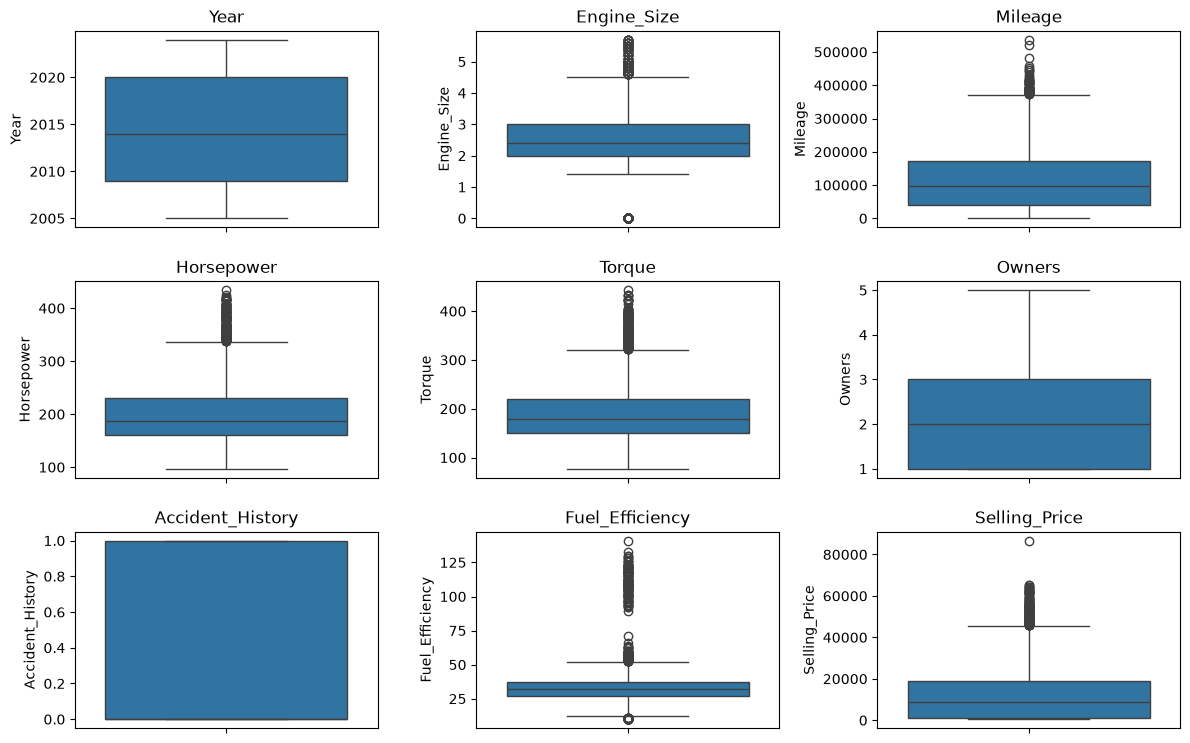

In [460]:
col = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12,15))

for i, col in enumerate(col, start=1):
    plt.subplot(6, 3, i)
    sns.boxplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2)
plt.show()

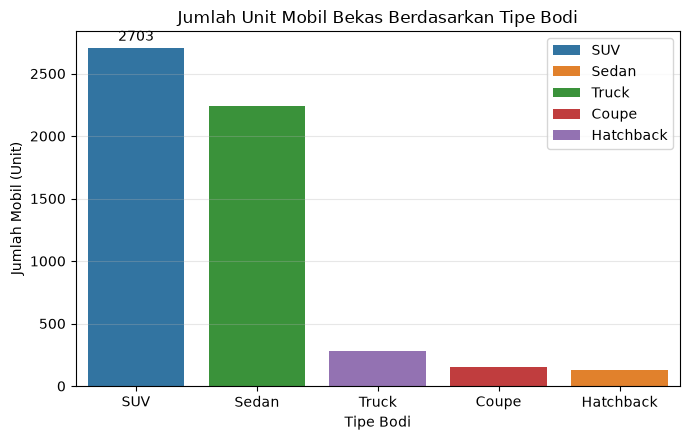

In [461]:
label_body = {0: 'SUV', 1: 'Hatchback', 2: 'Sedan', 3: 'Coupe', 4: 'Truck'}
body_counts = df['Body_Type'].replace(label_body).value_counts()

plt.figure(figsize=(7, 4.5))
body_order = df['Body_Type'].value_counts().index
ax = sns.countplot(x='Body_Type', data=df, order=body_order, hue='Body_Type', legend=False)

plt.title('Jumlah Unit Mobil Bekas Berdasarkan Tipe Bodi')
plt.xlabel('Tipe Bodi')
plt.ylabel('Jumlah Mobil (Unit)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(labels=body_order)
plt.tight_layout()

ax.bar_label(ax.containers[0], padding=3)
plt.show()

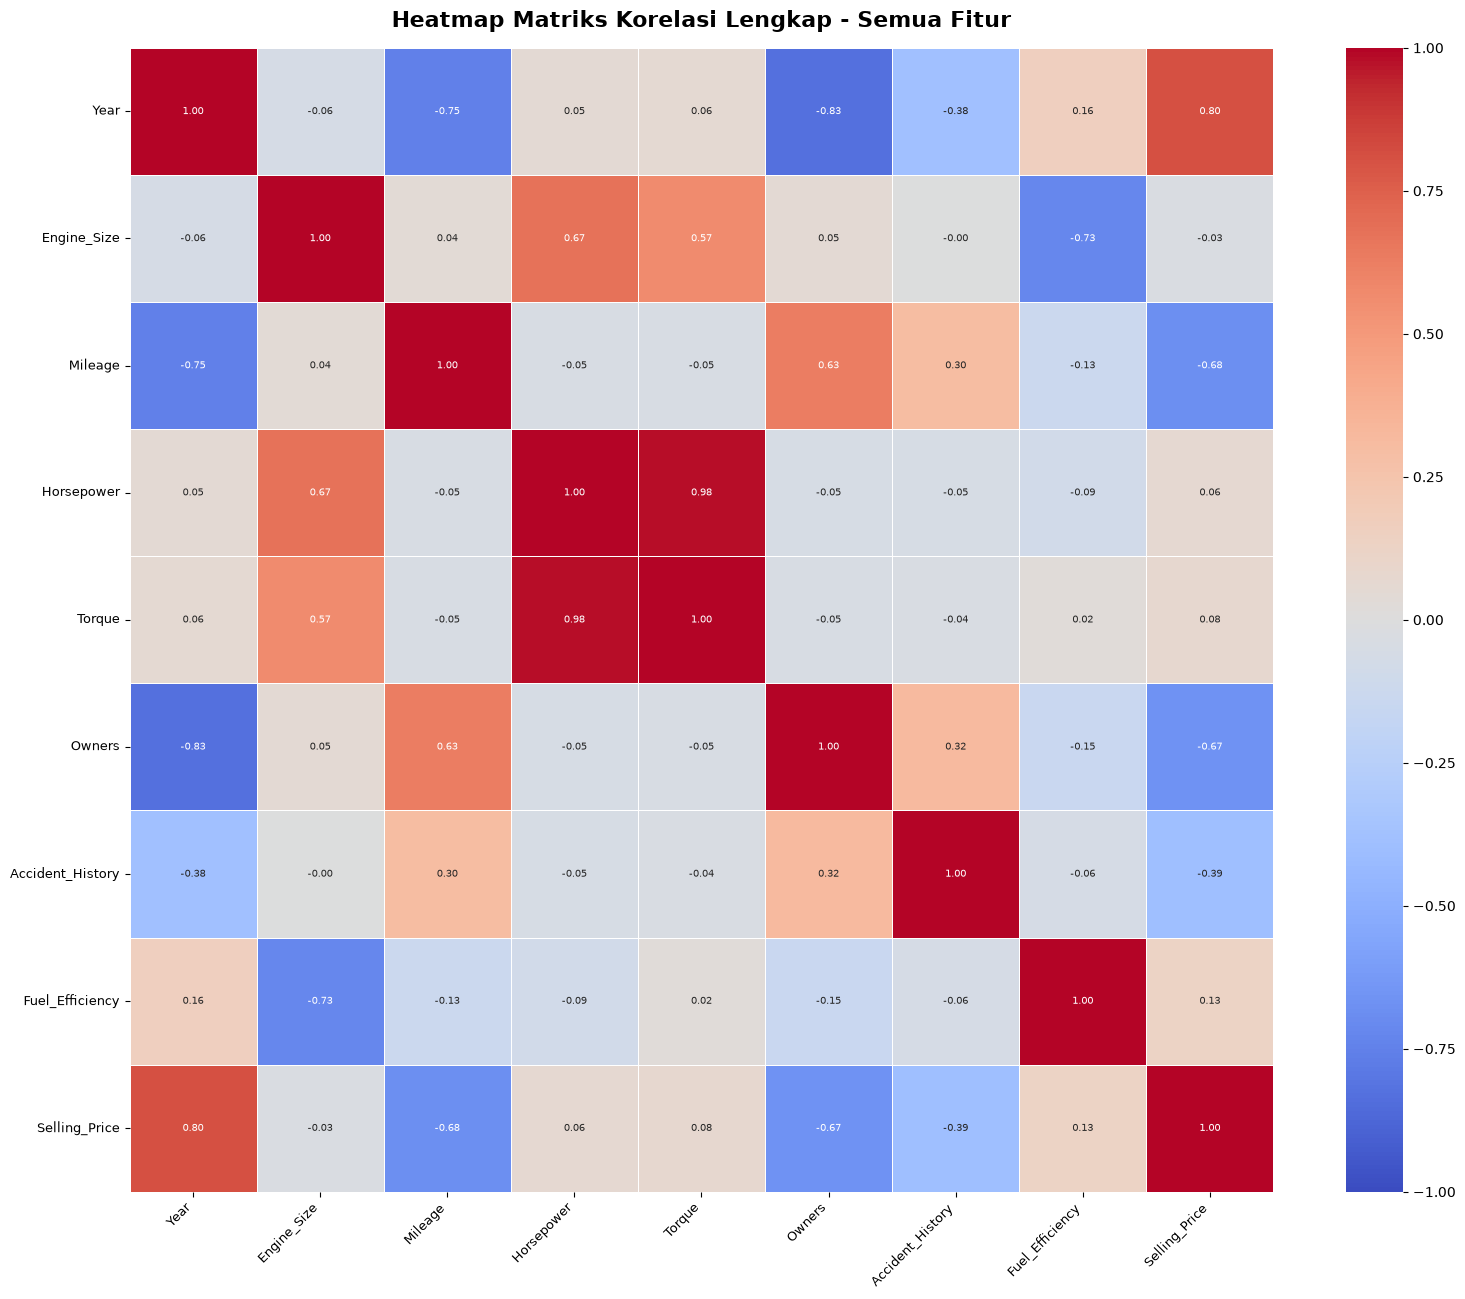

In [462]:
df_corr = df.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(16, 13))
sns.heatmap(
    df_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor='white',
    square=True,
    annot_kws={'size': 7.5}
)
plt.title('Heatmap Matriks Korelasi Lengkap - Semua Fitur', fontsize=16, pad=15, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

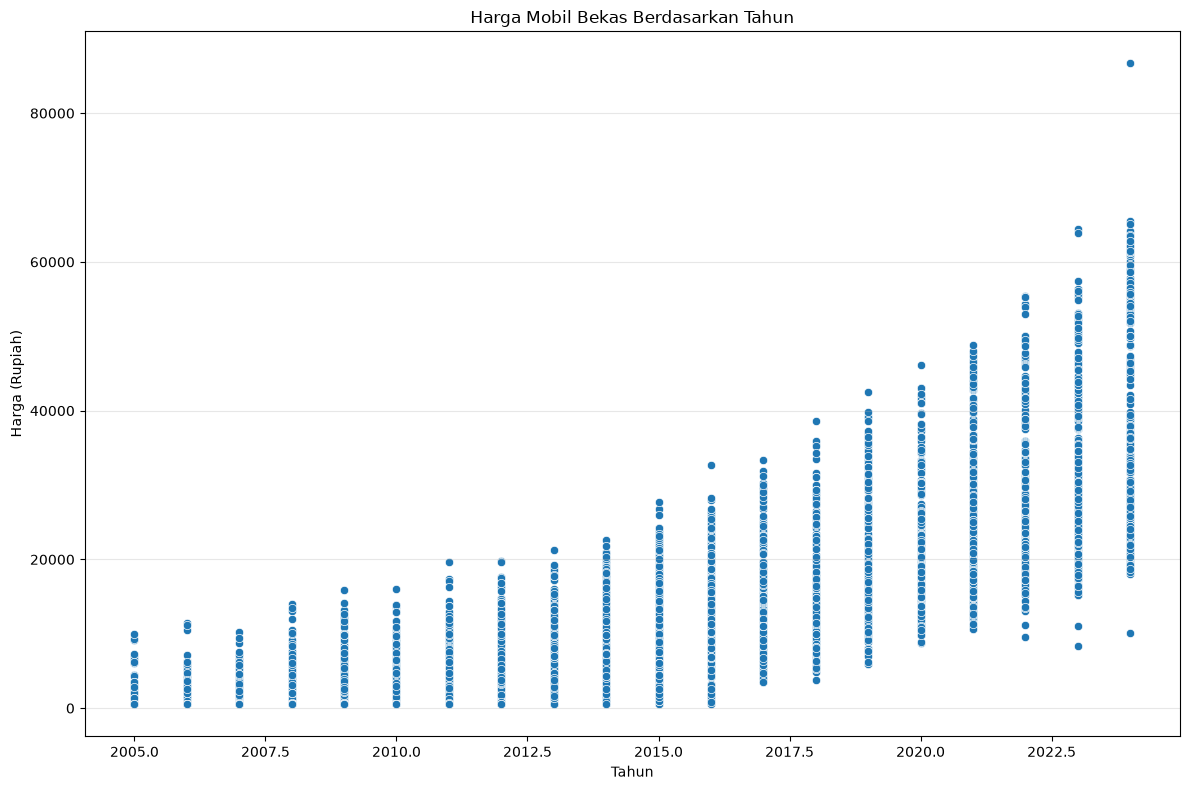

In [463]:
plt.figure(figsize=(12, 8))

sns.scatterplot(x='Year', y='Selling_Price', data=df)
plt.title('Harga Mobil Bekas Berdasarkan Tahun')
plt.xlabel('Tahun')
plt.ylabel('Harga (Rupiah)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


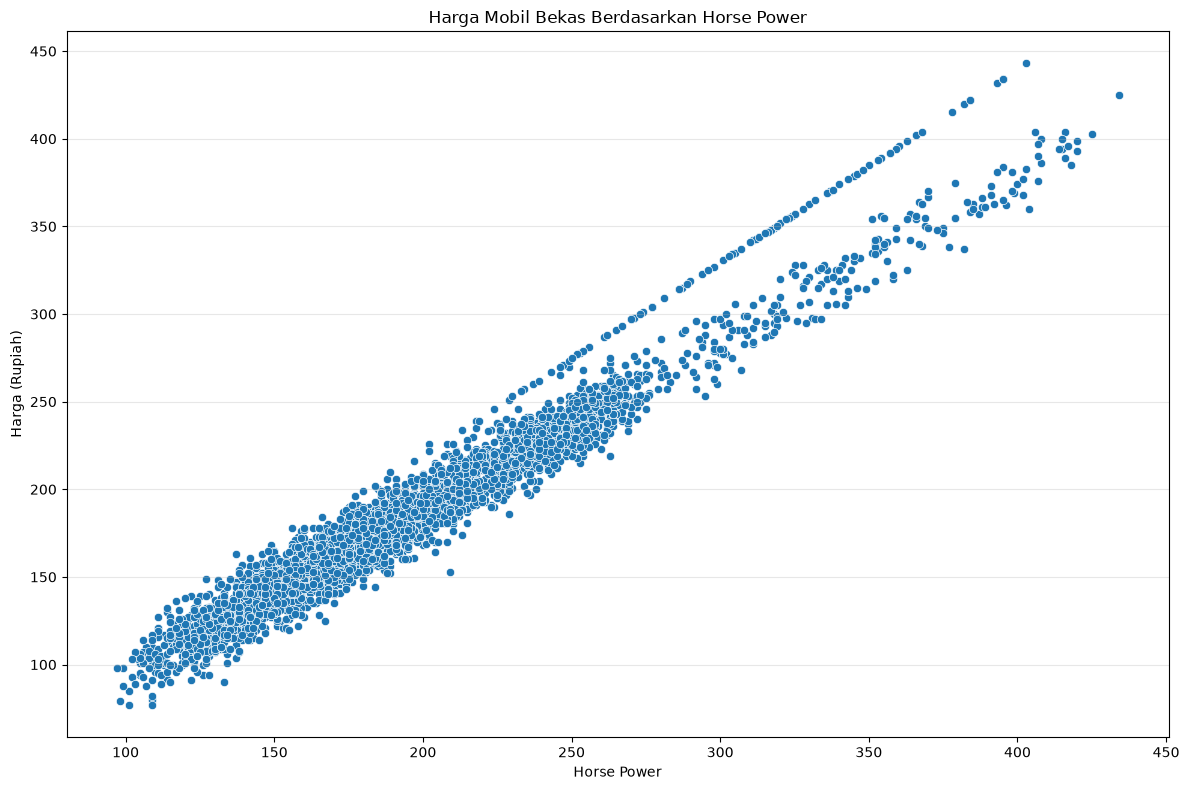

In [464]:
plt.figure(figsize=(12, 8))

sns.scatterplot(x='Horsepower', y='Torque', data=df)
plt.title('Harga Mobil Bekas Berdasarkan Horse Power')
plt.xlabel('Horse Power')   
plt.ylabel('Harga (Rupiah)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# **4. Data Preprocessing**

In [465]:
X = df.drop(columns=['Selling_Price', 'Model'])
y = df[['Selling_Price']]

In [466]:
def split_data(X, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    X_train, X_test = X.iloc[idx[:split_ratio]], X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_data(X, y)

In [467]:
kolom_tek = X_train.select_dtypes(include=['object', 'category', 'string']).columns
for col in kolom_tek:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])

kolom_num = X_train.select_dtypes(include=['number']).columns
for col in kolom_num:
    X_train[col] = X_train[col].fillna(X_train[col].median())

# X_test juga harus diimputasi, pakai statistik dari X_train agar konsisten
for col in kolom_tek:
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

for col in kolom_num:
    X_test[col] = X_test[col].fillna(X_train[col].median())


In [468]:
X_train.isnull().sum()

Make                0
Year                0
Fuel_Type           0
Transmission        0
Engine_Size         0
Mileage             0
Horsepower          0
Torque              0
Owners              0
Accident_History    0
Service_History     0
Color               0
Body_Type           0
Drivetrain          0
Fuel_Efficiency     0
Location            0
dtype: int64

In [469]:
cols = X_train.select_dtypes(include=['number']).columns

Q1 = X_train[cols].quantile(0.25)
Q3 = X_train[cols].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((X_train[cols] < batas_bawah) | (X_train[cols] > batas_atas)).sum()

hasil = pd.DataFrame({'Outlier': outlier, 'Percentage': outlier / len(X_train) * 100})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Percentage
Fuel_Efficiency,334,7.590909
Engine_Size,278,6.318182
Torque,218,4.954545
Horsepower,185,4.204545
Mileage,43,0.977273
Year,0,0.000000
Owners,0,0.000000
Accident_History,0,0.000000


In [470]:
cols = X_train.select_dtypes(include=['number']).columns

Q1 = X_train[cols].quantile(0.25)
Q3 = X_train[cols].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

X_train[cols] = X_train[cols].clip(batas_bawah, batas_atas, axis=1)

outlier_capping = ((X_train[cols] < (Q1 - 1.5 * IQR)) | (X_train[cols] > (Q3 + 1.5 * IQR))).sum()

hasil = pd.DataFrame({'Outlier': outlier_capping, 'Percentage': outlier_capping / len(X_train) * 100})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Percentage
Year,0,0.0
Engine_Size,0,0.0
Mileage,0,0.0
Horsepower,0,0.0
Torque,0,0.0
Owners,0,0.0
Accident_History,0,0.0
Fuel_Efficiency,0,0.0


In [471]:
mapping_trans = {'Manual': 1, 'Automatic': 0}
mapping_service = {'No Service': 0, 'Partial Service': 1, 'Full Service': 2 }

X_train['Service_History'] = X_train['Service_History'].map(mapping_service)
X_test['Service_History'] = X_test['Service_History'].map(mapping_service)

X_train['Transmission'] = X_train['Transmission'].map(mapping_trans)
X_test['Transmission'] = X_test['Transmission'].map(mapping_trans)

kolom_number = ['Fuel_Type', 'Body_Type', 'Drivetrain', 'Make', 'Color', 'Location']

for col in kolom_number:
    kategori_train = X_train[col].dropna().unique()
    for kat in kategori_train:
        X_train[f"{col}_{kat}"] = (X_train[col] == kat).astype(int)
        X_test[f"{col}_{kat}"] = (X_test[col] == kat).astype(int)

    X_train = X_train.drop(columns=[col])
    X_test = X_test.drop(columns=[col])


In [472]:
X_train.head()

,Year,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Fuel_Efficiency,...,Location_NC,Location_TX,Location_FL,Location_GA,Location_NY,Location_IL,Location_MI,Location_PA,Location_OH,Location_CA
4747,2009,0,2.4,65574.0,183.0,177.0,4,0.0,2,28.0,...,1,0,0,0,0,0,0,0,0,0
1199,2005,1,2.3,223214.0,177.0,174.0,5,0.0,2,34.0,...,0,1,0,0,0,0,0,0,0,0
5222,2016,0,2.3,161069.0,126.0,116.0,2,1.0,1,37.0,...,0,0,1,0,0,0,0,0,0,0
4547,2015,0,2.7,94667.0,185.0,181.0,3,1.0,1,27.0,...,0,1,0,0,0,0,0,0,0,0
1862,2017,0,2.8,125178.0,224.0,218.0,2,0.0,0,27.0,...,0,1,0,0,0,0,0,0,0,0


## **5.0 Modeling**

In [473]:
class Node:
    def __init__(self, fitur_idx=None, threshold=None, var_reduction=None, mse=None, kiri=None, kanan=None, value = None):
        
        self.fitur_idx = fitur_idx
        self.threshold = threshold
        self.var_reduction = var_reduction
        self.mse = mse
        self.kiri = kiri
        self.kanan = kanan
        self.value = value
    

In [474]:
class Decisiontree:
    def __init__(self, min_samples_split=60, max_depth=4):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.root = None
        
    def variance(self, y):
        if len(y) == 0:
            return 0.0
        return np.var(y)
    
    def variance_reduction(self, parent_y, kiri_y, kanan_y):
        bobot_kiri = len(kiri_y) / len(parent_y)
        bobot_kanan = len(kanan_y) / len(parent_y)
        
        reduction = self.variance(parent_y) - (bobot_kiri * self.variance(kiri_y) + bobot_kanan * self.variance(kanan_y))
        return reduction
    
    def split(self, dataset, fitur_idx, threshold):
        mask = dataset[:, fitur_idx] <= threshold
        return dataset[mask], dataset[~mask]
    
    def best_split(self, dataset, n_fitur):
        best_split = {
            'fitur_idx': None,
            'threshold': None,
            'var_reduction': -1,
            'dataset_kiri': None,
            'dataset_kanan': None
        }
        parent_y = dataset[:, -1]
        
        for fitur_idx in range(n_fitur):
            values_fitur = dataset[:, fitur_idx]
            thresholds = np.unique(values_fitur)
            
            for threshold in thresholds:
                dataset_kiri, dataset_kanan = self.split(dataset, fitur_idx, threshold)
                
                if len(dataset_kiri) > 0 and len(dataset_kanan) > 0:
                    kiri_y = dataset_kiri[:, -1]
                    kanan_y = dataset_kanan[:, -1]
                    reduction = self.variance_reduction(parent_y, kiri_y, kanan_y)
                
                    # FIX: hapus self. di depan best_split
                    if reduction > best_split['var_reduction']:
                        best_split['fitur_idx'] = fitur_idx
                        best_split['threshold'] = threshold
                        best_split['var_reduction'] = reduction
                        best_split['dataset_kiri'] = dataset_kiri
                        best_split['dataset_kanan'] = dataset_kanan
                        
        return best_split
    
    def build_tree(self, dataset, curr_depth=0):
        X, y = dataset[:, :-1], dataset[:, -1]
        n_samples, n_fitur = X.shape
        curr_mse = self.variance(y)
        
        if n_samples >= self.min_samples_split and curr_depth <= self.max_depth and curr_mse > 0:
            best_split = self.best_split(dataset, n_fitur)
            
            if best_split['var_reduction'] > 0:
                node_kiri = self.build_tree(best_split['dataset_kiri'], curr_depth + 1)
                node_kanan = self.build_tree(best_split['dataset_kanan'], curr_depth + 1)
                
                return Node(
                    fitur_idx=best_split['fitur_idx'],
                    threshold=best_split['threshold'],
                    var_reduction=best_split['var_reduction'],
                    mse=curr_mse,
                    kiri=node_kiri,
                    kanan=node_kanan
                )
                
        
        leaf_value = np.mean(y)
        return Node(value=leaf_value, mse=curr_mse)
        
    def fit(self, X, y):
        
        X = np.array(X)
        y = np.array(y).reshape(-1, 1)
        dataset = np.concatenate([X, y], axis=1)
        self.root = self.build_tree(dataset)
        
    def predict(self, X):
        X = np.array(X)
        return np.array([self.predict_val(row, self.root) for row in X])
    
    def predict_val(self, row, node):
       
        if node.value is not None:
            return node.value
        
        if row[node.fitur_idx] <= node.threshold:
            return self.predict_val(row, node.kiri)
        else:
            return self.predict_val(row, node.kanan)



In [475]:
reg = Decisiontree(min_samples_split=60, max_depth=4)
reg.fit(X_train, y_train)

predictions = reg.predict(X_test)
y_test_arr = np.array(y_test).reshape(-1)

predictions_tr = reg.predict(X_train)
y_train_arr = np.array(y_train).reshape(-1)

mse = np.mean((y_test_arr - predictions) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test_arr - predictions))
r2 = 1 - (np.sum((y_test_arr - predictions) ** 2) / np.sum((y_test_arr - np.mean(y_test_arr)) ** 2))

mse_tr = np.mean((y_train_arr - predictions_tr) ** 2)
rmse_tr = np.sqrt(mse_tr)
mae_tr = np.mean(np.abs(y_train_arr - predictions_tr))
r2_tr = 1 - (np.sum((y_train_arr - predictions_tr) ** 2) / np.sum((y_train_arr - np.mean(y_train_arr)) ** 2))

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R^2  : {r2:.4f}")

print(f"MSE Train  : {mse_tr:.2f}")
print(f"RMSE Train: {rmse_tr:.2f}")
print(f"MAE  Train: {mae_tr:.2f}")
print(f"R^2  Train: {r2_tr:.4f}")


MSE  : 21939157.53
RMSE : 4683.93
MAE  : 3197.82
R^2  : 0.8484
MSE Train  : 21287523.53
RMSE Train: 4613.84
MAE  Train: 3278.29
R^2  Train: 0.8702


# **6.0 Visualisasi Decision Tree**

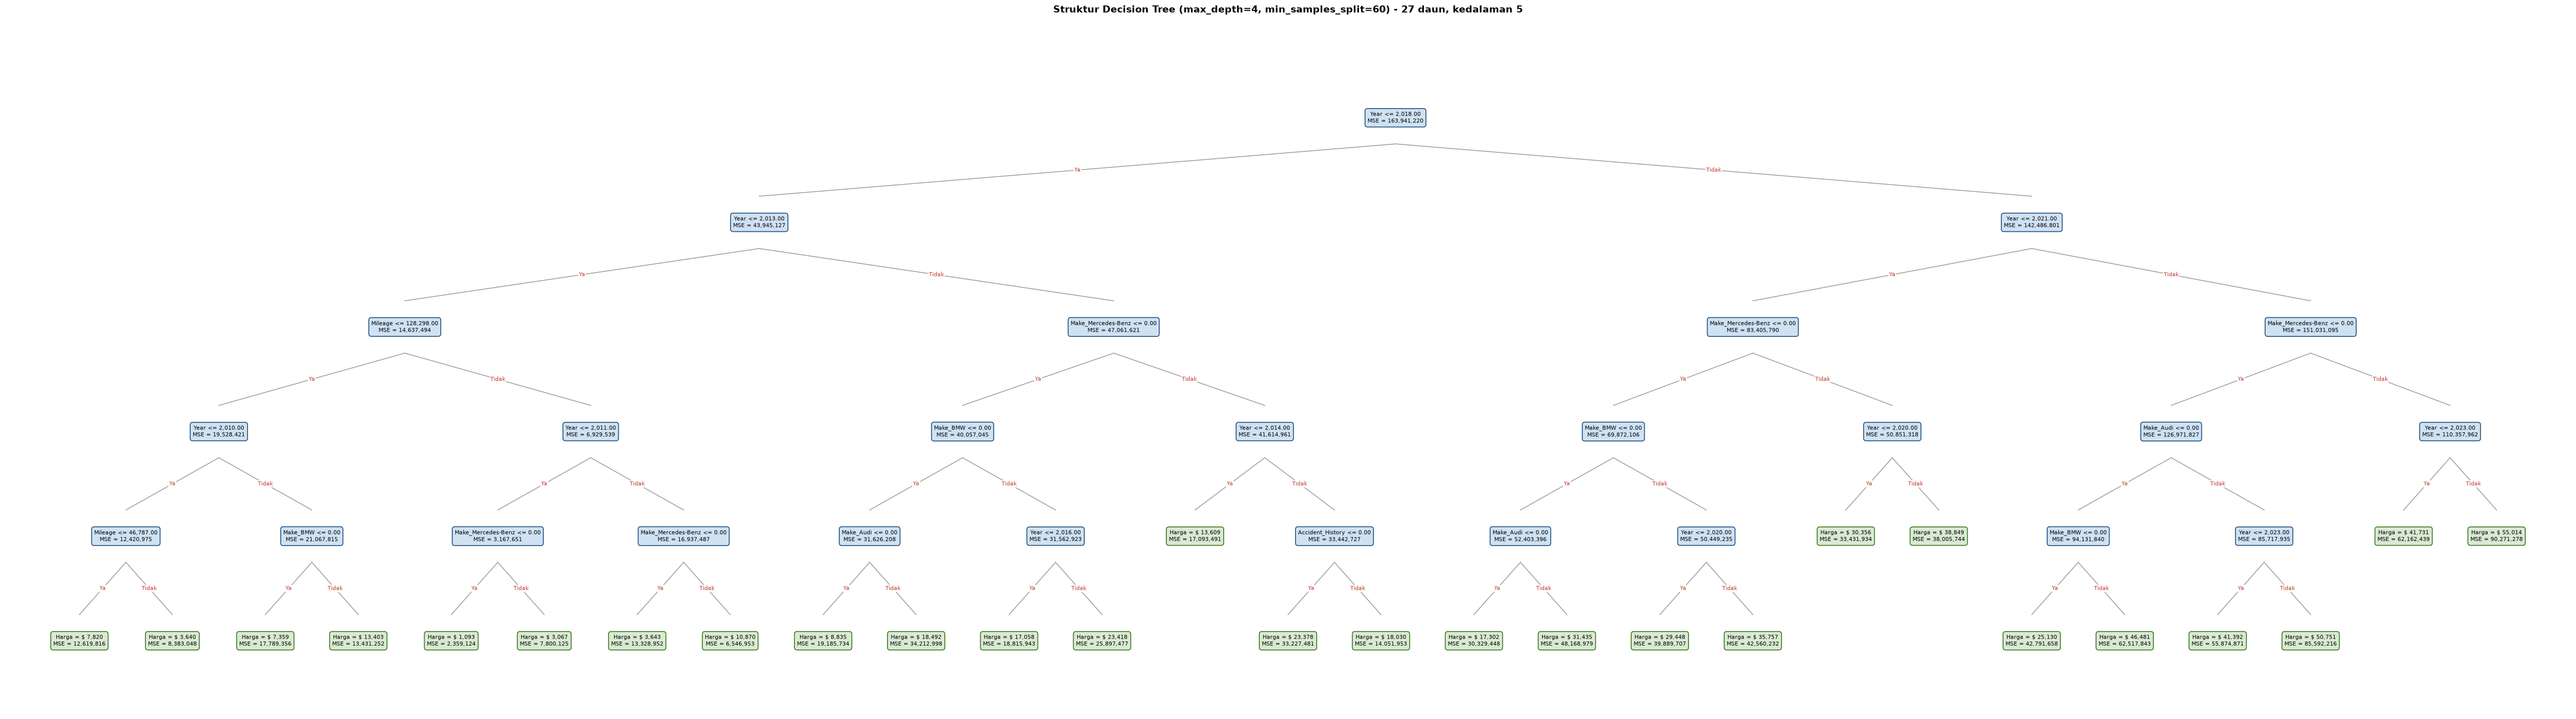

In [476]:
# ============================================================
# 6.1 Gambar Struktur Pohon Keputusan
# ============================================================
NAMA_FITUR = X_train.columns.tolist()      # indeks fitur -> nama kolom asli


def kedalaman_pohon(node):
    """Kedalaman maksimum dari sebuah node (daun = 0)."""
    if node.value is not None:
        return 0
    return 1 + max(kedalaman_pohon(node.kiri), kedalaman_pohon(node.kanan))


posisi = {}      # id(node) -> (x, kedalaman)
_daun = [0]      # penghitung daun, untuk menentukan posisi x


def atur_posisi(node, depth):
    """Hitung koordinat tiap node; daun berjejer rapi, node induk di tengah anaknya."""
    if node.value is not None:                     # daun
        posisi[id(node)] = (float(_daun[0]), depth)
        _daun[0] += 1
        return
    atur_posisi(node.kiri, depth + 1)
    atur_posisi(node.kanan, depth + 1)
    x = (posisi[id(node.kiri)][0] + posisi[id(node.kanan)][0]) / 2
    posisi[id(node)] = (x, depth)


atur_posisi(reg.root, 0)
depth_max = kedalaman_pohon(reg.root)
jumlah_daun = _daun[0]

fig, ax = plt.subplots(figsize=(max(14, jumlah_daun * 1.9), (depth_max + 1) * 2.4))
ax.axis("off")


def gambar_node(node):
    x, d = posisi[id(node)]
    y = -d

    if node.value is not None:                     # node daun -> nilai prediksi
        teks = f"Harga = $ {node.value:,.0f}\nMSE = {node.mse:,.0f}"
        warna, garis = "#d9ead3", "#38761d"
    else:                                          # node keputusan -> aturan split
        teks = (f"{NAMA_FITUR[node.fitur_idx]} <= {node.threshold:,.2f}\n"
                f"MSE = {node.mse:,.0f}")
        warna, garis = "#cfe2f3", "#1f4e79"

    ax.text(x, y, teks, ha="center", va="center", fontsize=8, zorder=2,
            bbox=dict(boxstyle="round,pad=0.45", facecolor=warna,
                      edgecolor=garis, linewidth=1.2))

    for anak, tanda in ((node.kiri, "Ya"), (node.kanan, "Tidak")):
        if anak is None:
            continue
        xa, d_a = posisi[id(anak)]
        ya = -d_a
        ax.plot([x, xa], [y - 0.25, ya + 0.25], color="#999999", linewidth=1.1, zorder=1)
        ax.text((x + xa) / 2, (y + ya) / 2, tanda, ha="center", va="center",
                fontsize=8, color="#c0392b", zorder=3,
                bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none"))
        gambar_node(anak)


gambar_node(reg.root)

ax.set_xlim(-0.8, jumlah_daun - 0.2)
ax.set_ylim(-depth_max - 0.7, 0.9)
ax.set_title(
    f"Struktur Decision Tree (max_depth={reg.max_depth}, "
    f"min_samples_split={reg.min_samples_split}) - {jumlah_daun} daun, kedalaman {depth_max}",
    fontsize=14, fontweight="bold", pad=16)

plt.tight_layout()
plt.show()


# **7.0 GUI**

In [477]:
# ============================================================
# 7.1 GUI Prediksi Harga Jual Mobil (Decision Tree Regressor)
# ============================================================

# ---- daftar kolom fitur final (urutannya sama dengan saat training) ----
FITUR = X_train.columns.tolist()

# ---- pemetaan kolom yang masih berupa teks ----
TRANSMISSION = {"Manual": 1, "Automatic": 0}
SERVICE = {"No Service": 0, "Partial Service": 1, "Full Service": 2}
ACCIDENT = {"Tidak Pernah": 0, "Pernah": 1}
INV_ACCIDENT = {v: k for k, v in ACCIDENT.items()}

# ---- kolom yang di-one-hot + daftar pilihannya ----
KOLOM_ONEHOT = ["Make", "Fuel_Type", "Color", "Body_Type", "Drivetrain", "Location"]
PILIHAN = {}
for col in KOLOM_ONEHOT:
    awalan = col + "_"
    # kategori dibaca dari nama kolom hasil encoding, jadi dijamin cocok
    PILIHAN[col] = sorted(c[len(awalan):] for c in FITUR if c.startswith(awalan))

# ---- kolom numerik: label tampilan + nilai default (median data latih) ----
NUMERIK_DEFAULT = {
    "Year": 2014, "Engine_Size": 2.4, "Mileage": 97000, "Horsepower": 187,
    "Torque": 178, "Owners": 2, "Fuel_Efficiency": 32.0,
}
NUMERIK_LABEL = {
    "Year": "Tahun Produksi",
    "Engine_Size": "Kapasitas Mesin (L)",
    "Mileage": "Jarak Tempuh (km)",
    "Horsepower": "Tenaga (HP)",
    "Torque": "Torsi (Nm)",
    "Owners": "Jumlah Pemilik",
    "Fuel_Efficiency": "Efisiensi BBM (mpg)",
}

# ---- dropdown untuk kolom teks non one-hot ----
COMBO_TAMBAHAN = [
    ("Transmission", "Transmisi", list(TRANSMISSION.keys())),
    ("Service_History", "Riwayat Servis", list(SERVICE.keys())),
    ("Accident_History", "Riwayat Kecelakaan", list(ACCIDENT.keys())),
]


def susun_baris(entries, combos):
    """Ubah isi form menjadi satu vektor fitur sesuai urutan kolom X_train."""
    nilai = {c: 0.0 for c in FITUR}

    # 1) kolom numerik diambil apa adanya dari input
    for col, entry in entries.items():
        teks = entry.get().strip().replace(",", ".")
        if teks == "":
            raise ValueError(f"'{NUMERIK_LABEL[col]}' tidak boleh kosong.")
        try:
            nilai[col] = float(teks)
        except ValueError:
            raise ValueError(f"'{NUMERIK_LABEL[col]}' harus berupa angka.")

    # 2) kolom teks yang dipetakan ke angka
    nilai["Transmission"] = TRANSMISSION[combos["Transmission"].get()]
    nilai["Service_History"] = SERVICE[combos["Service_History"].get()]
    nilai["Accident_History"] = float(ACCIDENT[combos["Accident_History"].get()])

    # 3) kolom one-hot: hanya kategori yang dipilih yang bernilai 1
    for col in KOLOM_ONEHOT:
        nama_kolom = f"{col}_{combos[col].get()}"
        if nama_kolom in nilai:
            nilai[nama_kolom] = 1.0

    return np.array([nilai[c] for c in FITUR], dtype=float)


class Aplikasi(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title("Prediksi Harga Jual Mobil Bekas")
        self.geometry("640x860")
        self.resizable(False, False)
        self.entries, self.combos = {}, {}
        self._bangun_form()

    def _bangun_form(self):
        header = tk.Frame(self, bg="#1f4e79", height=70)
        header.pack(fill="x")
        tk.Label(header, text="Prediksi Harga Jual Mobil Bekas", bg="#1f4e79",
                 fg="white", font=("Segoe UI", 15, "bold")).pack(pady=(12, 0))
        tk.Label(header, text="Metode Decision Tree Regressor (manual NumPy)",
                 bg="#1f4e79", fg="#cfe2f3", font=("Segoe UI", 10)).pack(pady=(0, 12))

        form = ttk.Frame(self, padding=20)
        form.pack(fill="both", expand=True)
        form.columnconfigure(1, weight=1)

        r = 0
        # kolom numerik
        for col, label in NUMERIK_LABEL.items():
            ttk.Label(form, text=label, font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", pady=4, padx=(0, 10))
            e = ttk.Entry(form, font=("Segoe UI", 10))
            e.insert(0, str(NUMERIK_DEFAULT[col]))
            e.grid(row=r, column=1, sticky="ew", pady=4)
            self.entries[col] = e
            r += 1

        # kolom one-hot
        for col in KOLOM_ONEHOT:
            ttk.Label(form, text=col.replace("_", " "), font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", pady=4, padx=(0, 10))
            c = ttk.Combobox(form, values=PILIHAN[col], state="readonly",
                             font=("Segoe UI", 10))
            c.current(0)
            c.grid(row=r, column=1, sticky="ew", pady=4)
            self.combos[col] = c
            r += 1

        # dropdown tambahan
        for col, label, pilihan in COMBO_TAMBAHAN:
            ttk.Label(form, text=label, font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", pady=4, padx=(0, 10))
            c = ttk.Combobox(form, values=pilihan, state="readonly",
                             font=("Segoe UI", 10))
            c.current(0)
            c.grid(row=r, column=1, sticky="ew", pady=4)
            self.combos[col] = c
            r += 1

        # tombol aksi
        btns = ttk.Frame(form)
        btns.grid(row=r, column=0, columnspan=2, sticky="ew", pady=(16, 6))
        btns.columnconfigure((0, 1, 2), weight=1)
        ttk.Button(btns, text="Isi Otomatis", command=self.on_autofill).grid(
            row=0, column=0, sticky="ew", padx=(0, 5), ipady=6)
        ttk.Button(btns, text="Prediksi", command=self.on_predict).grid(
            row=0, column=1, sticky="ew", padx=5, ipady=6)
        ttk.Button(btns, text="Reset", command=self.on_reset).grid(
            row=0, column=2, sticky="ew", padx=(5, 0), ipady=6)

        # area hasil
        self.result_var = tk.StringVar(value="Isi data mobil lalu tekan Prediksi.")
        self.result_label = tk.Label(form, textvariable=self.result_var,
                                     font=("Segoe UI", 13, "bold"), bg="#f2f2f2",
                                     fg="#333333", wraplength=520, justify="center",
                                     pady=16)
        self.result_label.grid(row=r + 1, column=0, columnspan=2, sticky="ew",
                               pady=(6, 0))

        tk.Label(self, text=f"Model siap - R2 uji {r2:.3f} | MAE uji {mae:,.0f}",
                 font=("Segoe UI", 9), fg="#666666").pack(side="bottom", pady=6)

    # ---------------- aksi tombol ----------------
    def _isi_form(self, baris):
        """Isi form dari satu baris data nyata (dipakai tombol Isi Otomatis)."""
        for col, entry in self.entries.items():
            v = baris[col]
            if pd.notna(v):
                entry.delete(0, tk.END)
                entry.insert(0, str(int(v)) if float(v).is_integer() else str(v))

        for col in KOLOM_ONEHOT:
            v = baris[col]
            if pd.notna(v) and v in PILIHAN[col]:
                self.combos[col].set(v)

        if pd.notna(baris["Transmission"]):
            self.combos["Transmission"].set(baris["Transmission"])
        if pd.notna(baris["Service_History"]):
            self.combos["Service_History"].set(baris["Service_History"])
        if pd.notna(baris["Accident_History"]):
            self.combos["Accident_History"].set(INV_ACCIDENT[int(baris["Accident_History"])])

    def on_autofill(self):
        self._isi_form(df.sample(n=1).iloc[0])
        self.result_var.set("Data contoh terisi otomatis. Tekan Prediksi untuk melihat hasil.")
        self.result_label.configure(bg="#f2f2f2", fg="#333333")
    
    def on_predict(self):
        try:
            # Mengambil input terbaru dari GUI
            x = susun_baris(self.entries, self.combos)

            # Debug input
            print("\n===== CEK INPUT GUI =====")
            print("Mileage GUI:", self.entries["Mileage"].get())
            print("Mileage Model:", x[FITUR.index("Mileage")])
            print("Jumlah fitur:", len(x))
            print("Jumlah fitur training:", len(FITUR))

            # Prediksi
            harga = float(reg.predict(x.reshape(1, -1))[0])

            # Menampilkan hasil
            print(f"Hasil Prediksi: ${harga:,.2f}")

            self.result_var.set(
                f"Perkiraan Harga Jual:\n$ {harga:,.2f}"
            )

            self.result_label.configure(
                bg="#d9ead3",
                fg="#1e6b34"
            )

        except ValueError as exc:
            messagebox.showwarning("Input tidak valid", str(exc))

        except Exception as exc:
            messagebox.showerror("Terjadi Kesalahan", str(exc))



    def on_reset(self):
        for col, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, str(NUMERIK_DEFAULT[col]))
        for combo in self.combos.values():
            combo.current(0)
        self.result_var.set("Isi data mobil lalu tekan Prediksi.")
        self.result_label.configure(bg="#f2f2f2", fg="#333333")


# ---- jalankan aplikasi ----
app = Aplikasi()
app.mainloop()



===== CEK INPUT GUI =====
Mileage GUI: 97000
Mileage Model: 97000.0
Jumlah fitur: 51
Jumlah fitur training: 51
Hasil Prediksi: $18,491.70

===== CEK INPUT GUI =====
Mileage GUI: 143441
Mileage Model: 143441.0
Jumlah fitur: 51
Jumlah fitur training: 51
Hasil Prediksi: $8,835.09

===== CEK INPUT GUI =====
Mileage GUI: 144687
Mileage Model: 144687.0
Jumlah fitur: 51
Jumlah fitur training: 51
Hasil Prediksi: $3,642.76

===== CEK INPUT GUI =====
Mileage GUI: 144687
Mileage Model: 144687.0
Jumlah fitur: 51
Jumlah fitur training: 51
Hasil Prediksi: $3,642.76

===== CEK INPUT GUI =====
Mileage GUI: 144687
Mileage Model: 144687.0
Jumlah fitur: 51
Jumlah fitur training: 51
Hasil Prediksi: $3,642.76

===== CEK INPUT GUI =====
Mileage GUI: 144687
Mileage Model: 144687.0
Jumlah fitur: 51
Jumlah fitur training: 51
Hasil Prediksi: $3,642.76
